# **SpaceX Falcon 9 First Stage Landing Prediction**
## **Lab 4: Exploratory Data Analysis (EDA) with Data Visualization & Feature Engineering**

In this lab, we perform visual Exploratory Data Analysis using `Matplotlib` and `Seaborn` on `dataset_part_2.csv` to uncover relationships between `FlightNumber`, `PayloadMass`, `LaunchSite`, `Orbit`, launch year, and first-stage landing outcome (`Class`). We then apply one-hot encoding (`pd.get_dummies`) to categorical features and export the modeling-ready feature matrix to `dataset_part_3.csv`.

### **Objectives**
* Visualize relationships between `FlightNumber`, `PayloadMass`, `LaunchSite`, and `Orbit` against `Class` using categorical scatter plots (`sns.catplot`).
* Compare landing success rates across orbital regimes using bar charts (`sns.barplot`).
* Track annual landing success trends from 2010 to 2020 using line plots (`sns.lineplot`).
* Perform feature selection and one-hot encoding (`pd.get_dummies`) to create `dataset_part_3.csv`.

### **1. Import Libraries & Load Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")
print("Loaded dataset_part_2.csv — Shape:", df.shape)
df.head(5)

Loaded dataset_part_2.csv — Shape: (90, 18)


   FlightNumber        Date BoosterVersion  PayloadMass Orbit    LaunchSite    Outcome  Flights  GridFins  Reused   Legs LandingPad  Block  ReusedCount Serial   Longitude   Latitude  Class
0             1  2010-06-04       Falcon 9  6104.959412   LEO  CCSFS SLC 40  None None        1     False   False  False        NaN    1.0            0  B0003  -80.577366  28.561857      0
1             2  2012-05-22       Falcon 9   525.000000   LEO  CCSFS SLC 40  None None        1     False   False  False        NaN    1.0            0  B0005  -80.577366  28.561857      0
2             3  2013-03-01       Falcon 9   677.000000   ISS  CCSFS SLC 40  None None        1     False   False  False        NaN    1.0            0  B0007  -80.577366  28.561857      0
3             4  2013-09-29       Falcon 9   500.000000    PO   VAFB SLC 4E  False Ocean       1     False   False  False        NaN    1.0            0  B1003 -120.610829  34.632093      0
4             5  2013-12-03       Falcon 9  3170.00000

### **2. Task 1 & Task 2: Visualize Flight Number & Payload Mass vs. Launch Site**

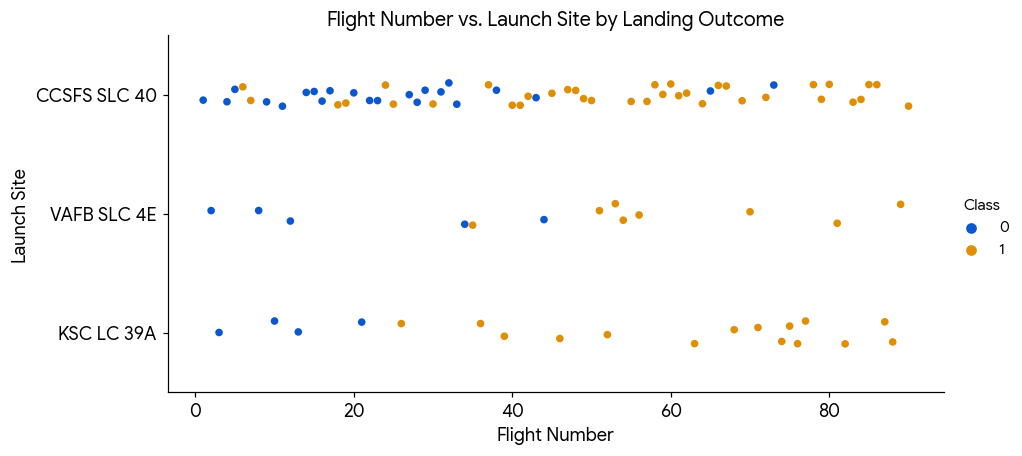

In [2]:
# Task 1: Scatter plot of Flight Number vs. Launch Site colored by Class
sns.catplot(y="LaunchSite", x="FlightNumber", hue="Class", data=df, aspect=2.2)
plt.xlabel("Flight Number", fontsize=12)
plt.ylabel("Launch Site", fontsize=12)
plt.title("Flight Number vs. Launch Site by Landing Outcome", fontsize=13)
plt.show()

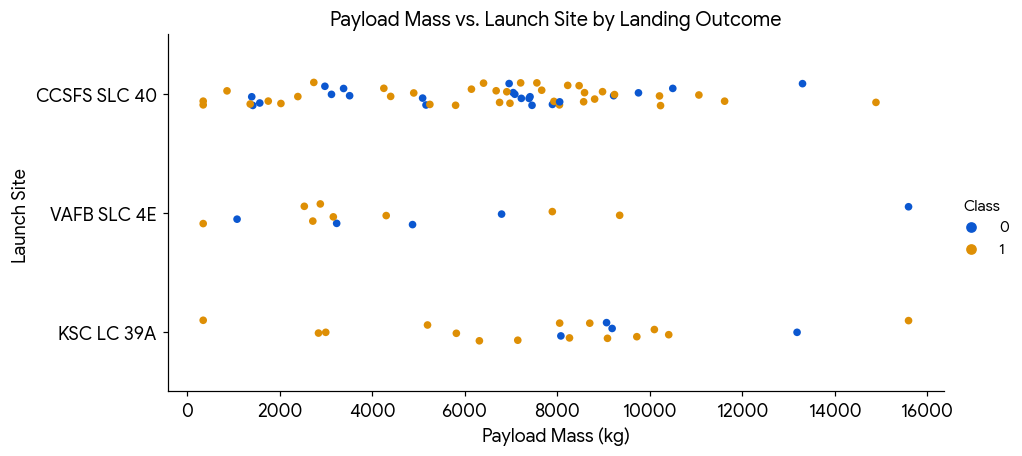

In [3]:
# Task 2: Scatter plot of Payload Mass vs. Launch Site colored by Class
sns.catplot(y="LaunchSite", x="PayloadMass", hue="Class", data=df, aspect=2.2)
plt.xlabel("Payload Mass (kg)", fontsize=12)
plt.ylabel("Launch Site", fontsize=12)
plt.title("Payload Mass vs. Launch Site by Landing Outcome", fontsize=13)
plt.show()

### **3. Task 3: Visualize Success Rate of Each Orbit Type**

Orbit    Class
ES-L1 1.000000
  GEO 1.000000
  HEO 1.000000
  SSO 1.000000
 VLEO 0.857143
  LEO 0.714286
  MEO 0.666667
   PO 0.666667
  ISS 0.619048
  GTO 0.518519
   SO 0.000000


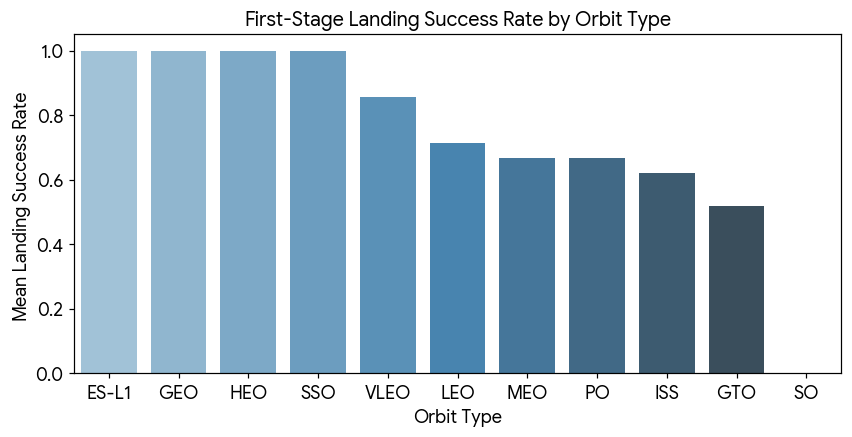

In [4]:
# Task 3: Bar chart of mean landing success rate grouped by Orbit
orbit_success = df.groupby('Orbit')['Class'].mean().reset_index().sort_values(by='Class', ascending=False)
print(orbit_success.to_string(index=False))

plt.figure(figsize=(9, 4))
sns.barplot(x='Orbit', y='Class', data=orbit_success, palette='Blues_d')
plt.xlabel("Orbit Type", fontsize=12)
plt.ylabel("Mean Landing Success Rate", fontsize=12)
plt.title("First-Stage Landing Success Rate by Orbit Type", fontsize=13)
plt.show()

### **4. Task 4 & Task 5: Visualize Flight Number & Payload Mass vs. Orbit Type**

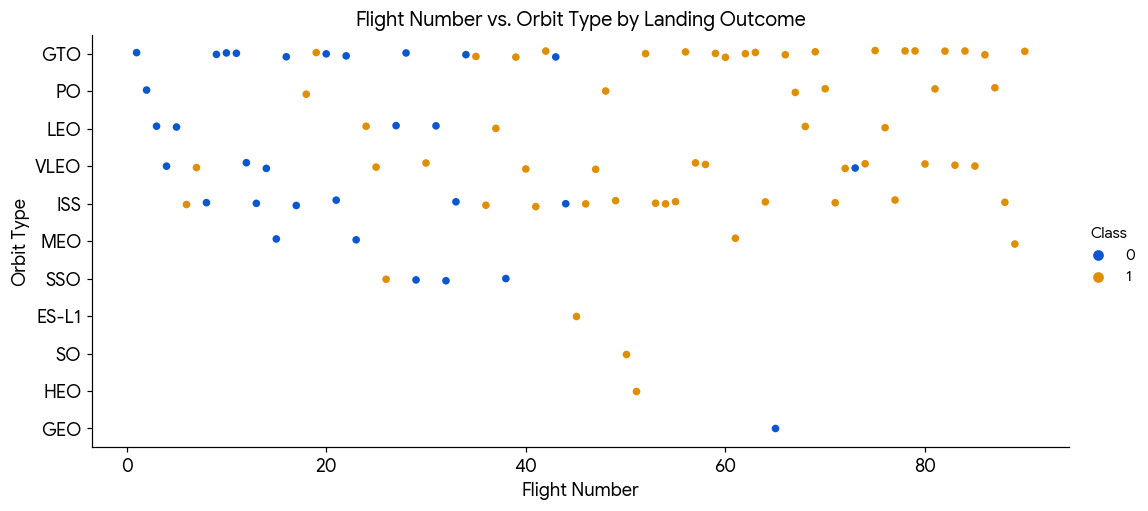

In [5]:
# Task 4: Scatter plot of Flight Number vs. Orbit Type
sns.catplot(y="Orbit", x="FlightNumber", hue="Class", data=df, aspect=2.2)
plt.xlabel("Flight Number", fontsize=12)
plt.ylabel("Orbit Type", fontsize=12)
plt.title("Flight Number vs. Orbit Type by Landing Outcome", fontsize=13)
plt.show()

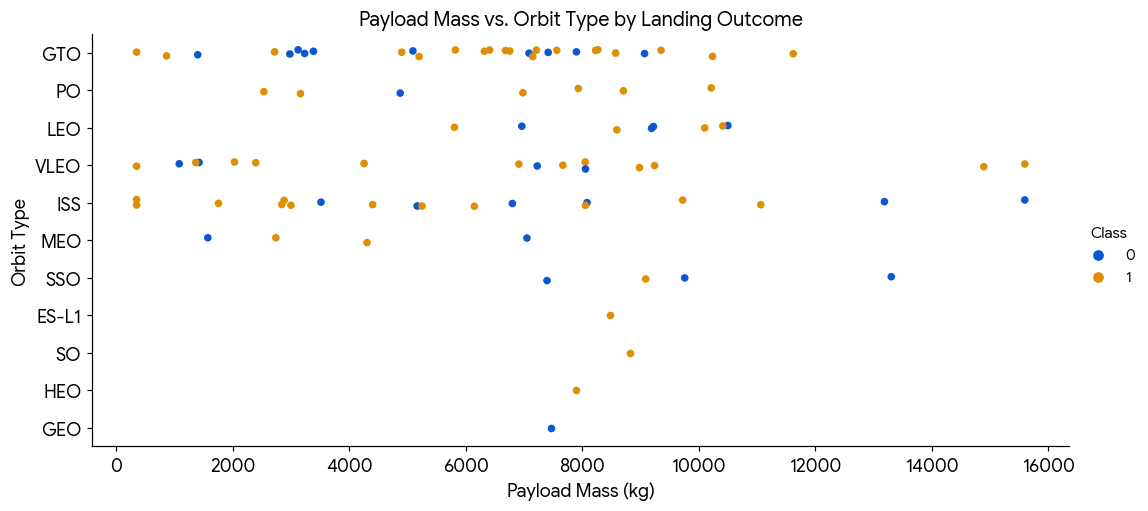

In [6]:
# Task 5: Scatter plot of Payload Mass vs. Orbit Type
sns.catplot(y="Orbit", x="PayloadMass", hue="Class", data=df, aspect=2.2)
plt.xlabel("Payload Mass (kg)", fontsize=12)
plt.ylabel("Orbit Type", fontsize=12)
plt.title("Payload Mass vs. Orbit Type by Landing Outcome", fontsize=13)
plt.show()

### **5. Task 6: Visualize Launch Success Yearly Trend**

 Year    Class
 2010 0.000000
 2012 0.000000
 2013 0.000000
 2014 0.333333
 2015 0.333333
 2016 0.625000
 2017 0.833333
 2018 0.611111
 2019 0.900000
 2020 0.842105


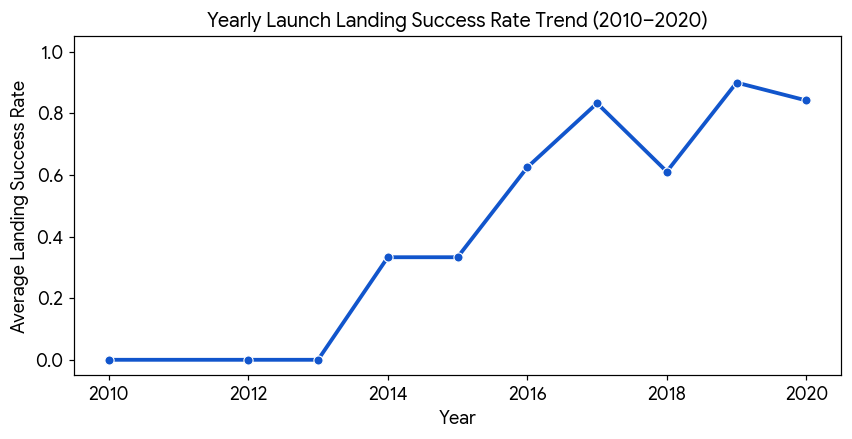

In [7]:
# Extract Year from Date and plot annual average landing success rate
df['Year'] = pd.to_datetime(df['Date']).dt.year
yearly_trend = df.groupby('Year')['Class'].mean().reset_index()
print(yearly_trend.to_string(index=False))

plt.figure(figsize=(9, 4))
sns.lineplot(x='Year', y='Class', data=yearly_trend, marker='o', linewidth=2.5, color='#1155CC')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Landing Success Rate", fontsize=12)
plt.title("Yearly Launch Landing Success Rate Trend (2010–2020)", fontsize=13)
plt.ylim(-0.05, 1.05)
plt.show()

### **6. Task 7 & Task 8: Feature Engineering & One-Hot Encoding (`dataset_part_3.csv`)**

In [8]:
# Select predictive features for machine learning models
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights',
               'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]

# Apply one-hot encoding to categorical columns
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])

# Cast all columns to float64
features_one_hot = features_one_hot.astype('float64')

print("One-Hot Encoded Feature Matrix Shape:", features_one_hot.shape)
features_one_hot.to_csv('dataset_part_3.csv', index=False)
print("Successfully exported dataset_part_3.csv (90 rows, 83 columns).")
features_one_hot.head(5)

One-Hot Encoded Feature Matrix Shape: (90, 83)
Successfully exported dataset_part_3.csv (90 rows, 83 columns).


   FlightNumber  PayloadMass  Flights  GridFins  Reused  Legs  Block  ReusedCount  Orbit_ES-L1  Orbit_GEO  Orbit_GTO  Orbit_HEO  Orbit_ISS  Orbit_LEO  Orbit_MEO  Orbit_PO  Orbit_SO  Orbit_SSO  Orbit_VLEO  LaunchSite_CCSFS SLC 40  LaunchSite_KSC LC 39A  LaunchSite_VAFB SLC 4E
0           1.0  6104.959412      1.0       0.0     0.0   0.0    1.0          0.0          0.0        0.0        0.0        0.0        0.0        1.0        0.0       0.0       0.0        0.0         0.0                      1.0                    0.0                     0.0
1           2.0   525.000000      1.0       0.0     0.0   0.0    1.0          0.0          0.0        0.0        0.0        0.0        0.0        1.0        0.0       0.0       0.0        0.0         0.0                      1.0                    0.0                     0.0
2           3.0   677.000000      1.0       0.0     0.0   0.0    1.0          0.0          0.0        0.0        0.0        0.0        1.0        0.0        0.0       0.0  